In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:
df=pd.read_csv(r"C:\Users\syeda\Downloads\EV_Charging_Network_Analytics_Dataset.csv")

In [4]:
df.head()

,Session_ID,Session_Start,City,Station_ID,Station_Type,Charger_Type,Vehicle_Type,Energy_kWh,Wait_Time_Min,Charging_Duration_Min,Revenue_INR,Customer_Rating,Payment_Mode
0,1,2024-11-27 04:25,Hyderabad,STN-137,Residential,AC 7kW,Taxi,58.70,32.0,37,613.41,4.0,Fleet Account
1,2,2024-03-12 07:05,Kochi,STN-130,Residential,AC 7kW,SUV,62.86,37.0,17,1063.92,4.0,UPI
2,3,2024-08-14 01:35,Chennai,STN-248,Office,DC 30kW,Bike,18.25,19.0,81,361.23,2.0,UPI
3,4,2025-08-18 18:40,Pune,STN-290,Urban,AC 7kW,Bike,13.19,13.0,73,239.59,4.0,Wallet
4,5,2025-04-21 18:59,Ahmedabad,STN-285,Mall,DC 30kW,SUV,68.81,15.0,20,1162.41,5.0,Fleet Account


In [5]:
df.shape

(100750, 13)

In [6]:
df.columns

Index(['Session_ID', 'Session_Start', 'City', 'Station_ID', 'Station_Type',
       'Charger_Type', 'Vehicle_Type', 'Energy_kWh', 'Wait_Time_Min',
       'Charging_Duration_Min', 'Revenue_INR', 'Customer_Rating',
       'Payment_Mode'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100750 entries, 0 to 100749
Data columns (total 13 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Session_ID             100750 non-null  int64  
 1   Session_Start          100750 non-null  object 
 2   City                   98738 non-null   object 
 3   Station_ID             100750 non-null  object 
 4   Station_Type           100750 non-null  object 
 5   Charger_Type           98739 non-null   object 
 6   Vehicle_Type           100750 non-null  object 
 7   Energy_kWh             100750 non-null  float64
 8   Wait_Time_Min          98758 non-null   float64
 9   Charging_Duration_Min  100750 non-null  int64  
 10  Revenue_INR            98741 non-null   float64
 11  Customer_Rating        98731 non-null   float64
 12  Payment_Mode           100750 non-null  object 
dtypes: float64(4), int64(2), object(7)
memory usage: 10.0+ MB


In [8]:
df.describe()

,Session_ID,Energy_kWh,Wait_Time_Min,Charging_Duration_Min,Revenue_INR,Customer_Rating
count,100750.000000,100750.000000,98758.000000,100750.000000,98741.000000,98731.000000
mean,50007.836467,51.466513,23.341380,64.910372,823.662315,2.999615
std,28866.611316,25.141925,18.137506,32.017072,448.754672,1.415123
min,1.000000,8.010000,0.000000,10.000000,80.790000,1.000000
25%,25014.250000,29.740000,11.000000,37.000000,453.450000,2.000000
50%,50016.500000,51.430000,22.000000,65.000000,781.470000,3.000000
75%,74999.750000,73.280000,34.000000,93.000000,1136.400000,4.000000
max,100000.000000,95.000000,219.000000,120.000000,2082.290000,5.000000


In [9]:
df.describe(include='object')

,Session_Start,City,Station_ID,Station_Type,Charger_Type,Vehicle_Type,Payment_Mode
count,100750,98738,100750,100750,98739,100750,100750
unique,95309,8,300,5,4,5,4
top,2025-12-08 21:35,Pune,STN-345,Highway,AC 7kW,Taxi,Card
freq,4,12419,380,20410,24912,20321,25281


In [10]:
df.nunique()

Session_ID               100000
Session_Start             95309
City                          8
Station_ID                  300
Station_Type                  5
Charger_Type                  4
Vehicle_Type                  5
Energy_kWh                 8700
Wait_Time_Min                92
Charging_Duration_Min       111
Revenue_INR               73376
Customer_Rating               5
Payment_Mode                  4
dtype: int64

In [11]:
df.dtypes

Session_ID                 int64
Session_Start             object
City                      object
Station_ID                object
Station_Type              object
Charger_Type              object
Vehicle_Type              object
Energy_kWh               float64
Wait_Time_Min            float64
Charging_Duration_Min      int64
Revenue_INR              float64
Customer_Rating          float64
Payment_Mode              object
dtype: object

In [12]:
df.isnull().sum()

Session_ID                  0
Session_Start               0
City                     2012
Station_ID                  0
Station_Type                0
Charger_Type             2011
Vehicle_Type                0
Energy_kWh                  0
Wait_Time_Min            1992
Charging_Duration_Min       0
Revenue_INR              2009
Customer_Rating          2019
Payment_Mode                0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(750)

In [9]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_%': df.isnull().mean() * 100
})

missing = missing[missing['Missing_Count'] > 0].sort_values(
    'Missing_%', ascending=False
)

missing

,Missing_Count,Missing_%
Customer_Rating,2019,2.003970
City,2012,1.997022
Charger_Type,2011,1.996030
Revenue_INR,2009,1.994045
Wait_Time_Min,1992,1.977171


In [14]:
df_clean=df.drop_duplicates().copy()

In [15]:
df_clean.duplicated().sum()

np.int64(0)

In [12]:
df_clean[['Wait_Time_Min',
          'Revenue_INR',
          'Customer_Rating']].describe()

,Wait_Time_Min,Revenue_INR,Customer_Rating
count,98018.000000,98000.000000,98000.000000
mean,23.340652,823.808285,2.999755
std,18.146047,448.761371,1.415057
min,0.000000,80.790000,1.000000
25%,11.000000,453.570000,2.000000
50%,22.000000,781.435000,3.000000
75%,34.000000,1136.430000,4.000000
max,219.000000,2082.290000,5.000000


In [16]:
df_clean['City'] = df_clean['City'].fillna(
    df_clean['City'].mode()[0]
)

df_clean['Charger_Type'] = df_clean['Charger_Type'].fillna(
    df_clean['Charger_Type'].mode()[0]
)

In [17]:
df_clean['Wait_Time_Min'] = df_clean['Wait_Time_Min'].fillna(
    df_clean['Wait_Time_Min'].median()
)

df_clean['Revenue_INR'] = df_clean['Revenue_INR'].fillna(
    df_clean['Revenue_INR'].median()
)

df_clean['Customer_Rating'] = df_clean['Customer_Rating'].fillna(
    df_clean['Customer_Rating'].median()
)

In [18]:
df_clean.isnull().sum()

Session_ID               0
Session_Start            0
City                     0
Station_ID               0
Station_Type             0
Charger_Type             0
Vehicle_Type             0
Energy_kWh               0
Wait_Time_Min            0
Charging_Duration_Min    0
Revenue_INR              0
Customer_Rating          0
Payment_Mode             0
dtype: int64

In [19]:
df_clean.shape

(100000, 13)

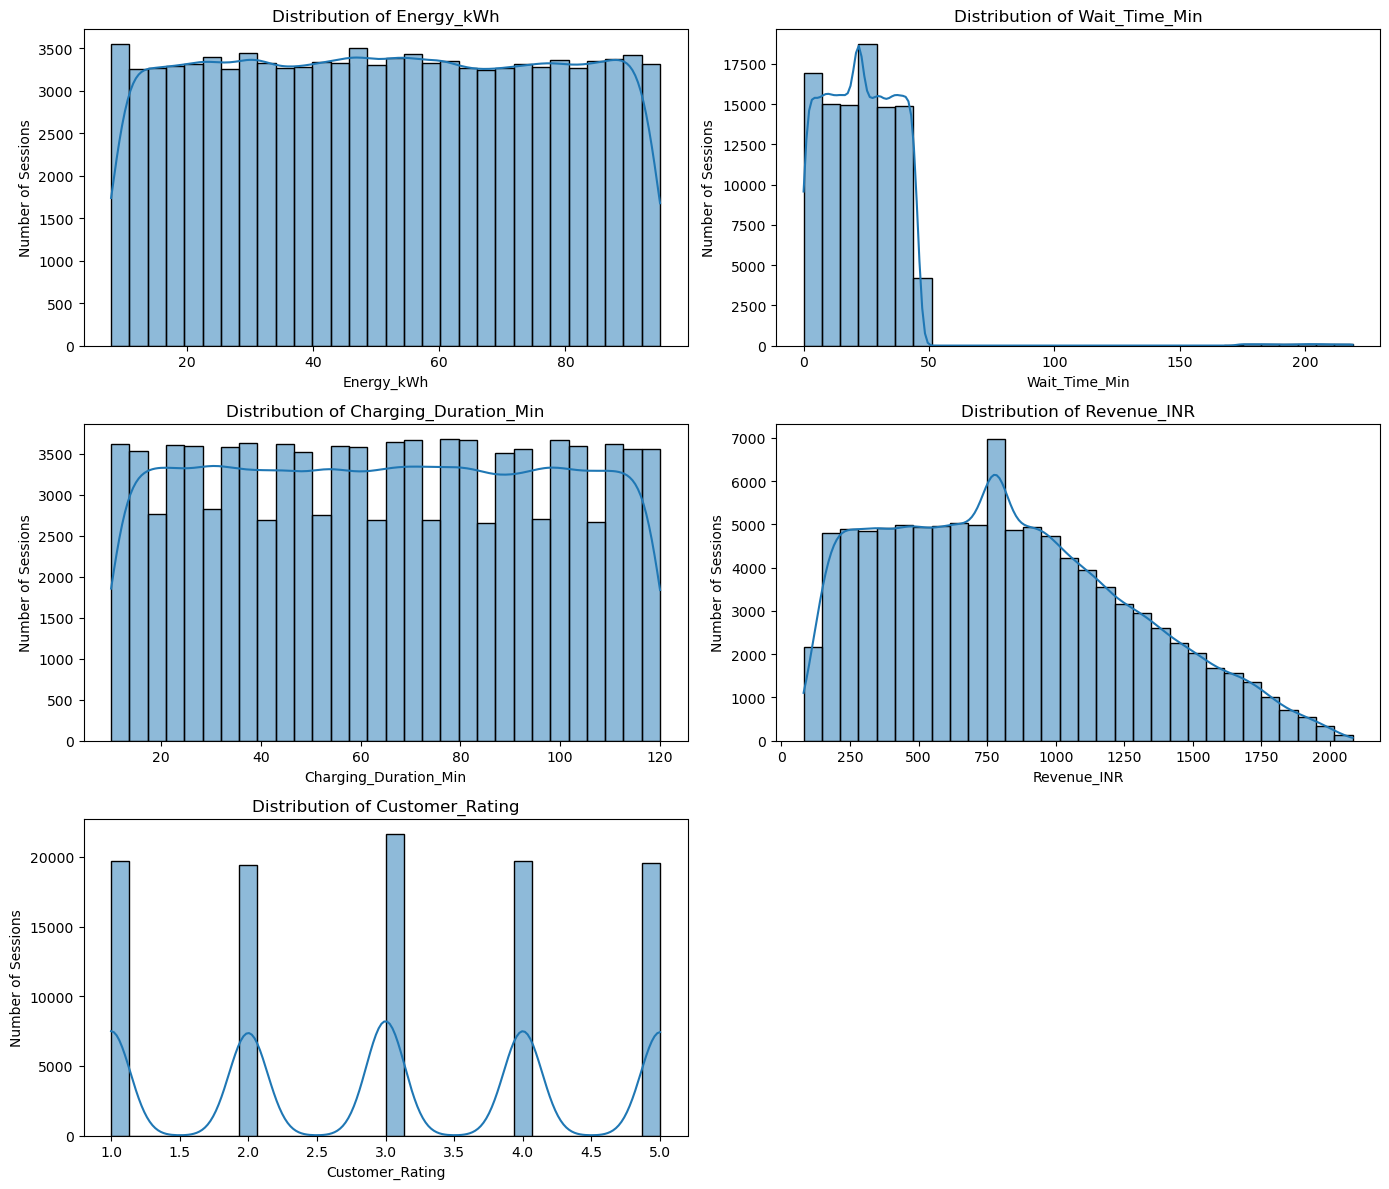

In [20]:
columns = [
    'Energy_kWh',
    'Wait_Time_Min',
    'Charging_Duration_Min',
    'Revenue_INR',
    'Customer_Rating'
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, col in zip(axes.flat, columns):
    sns.histplot(df_clean[col], bins=30, kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Number of Sessions')

# Remove the empty 6th plot
axes.flat[-1].set_visible(False)

plt.tight_layout()
plt.show()

In [17]:
#outliers
outlier_cols = [
    'Energy_kWh',
    'Wait_Time_Min',
    'Charging_Duration_Min',
    'Revenue_INR'
]

In [21]:
for col in outlier_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()

    print(col)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Outliers:", outliers)
    print()

NameError: name 'outlier_cols' is not defined

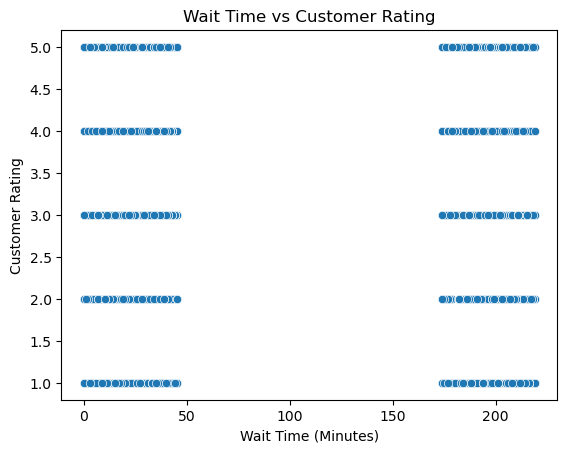

In [19]:
#Wait Time ↔ Customer Rating 
sns.scatterplot(
    data=df_clean,
    x='Wait_Time_Min',
    y='Customer_Rating'
)

plt.title('Wait Time vs Customer Rating')
plt.xlabel('Wait Time (Minutes)')
plt.ylabel('Customer Rating')
plt.show()

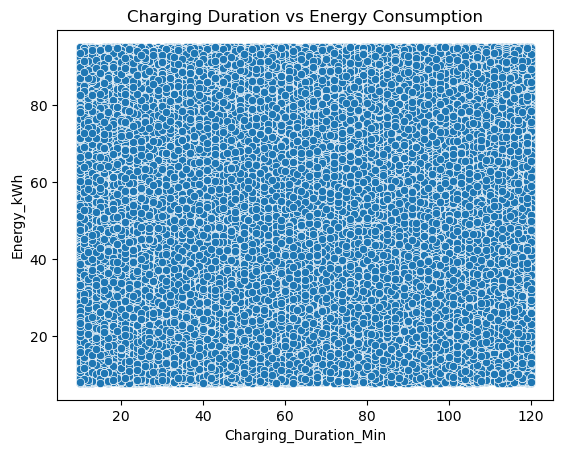

In [21]:
#Charging Duration ↔ Energy Consumed
sns.scatterplot(
    data=df_clean,
    x='Charging_Duration_Min',
    y='Energy_kWh'
)

plt.title('Charging Duration vs Energy Consumption')
plt.show()

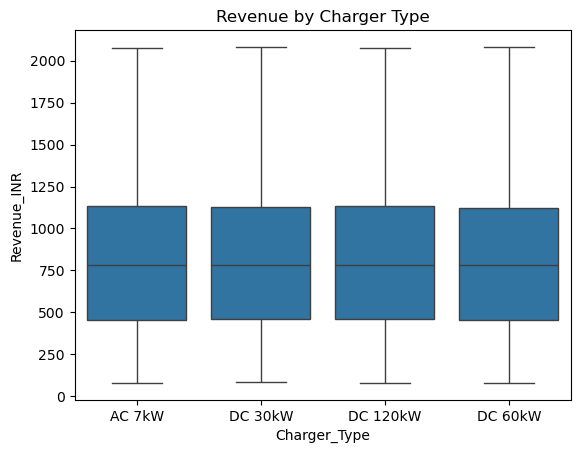

In [22]:
#Charger Type ↔ Revenue
sns.boxplot(
    data=df_clean,
    x='Charger_Type',
    y='Revenue_INR'
)

plt.title('Revenue by Charger Type')
plt.show()

In [23]:
#Convert Session_Start to datetime
df_clean['Session_Start'] = pd.to_datetime(
    df_clean['Session_Start'],
    errors='coerce'
)

In [24]:
#Extract time information
df_clean['Hour'] = df_clean['Session_Start'].dt.hour
df_clean['Day'] = df_clean['Session_Start'].dt.day_name()
df_clean['Month'] = df_clean['Session_Start'].dt.month_name()

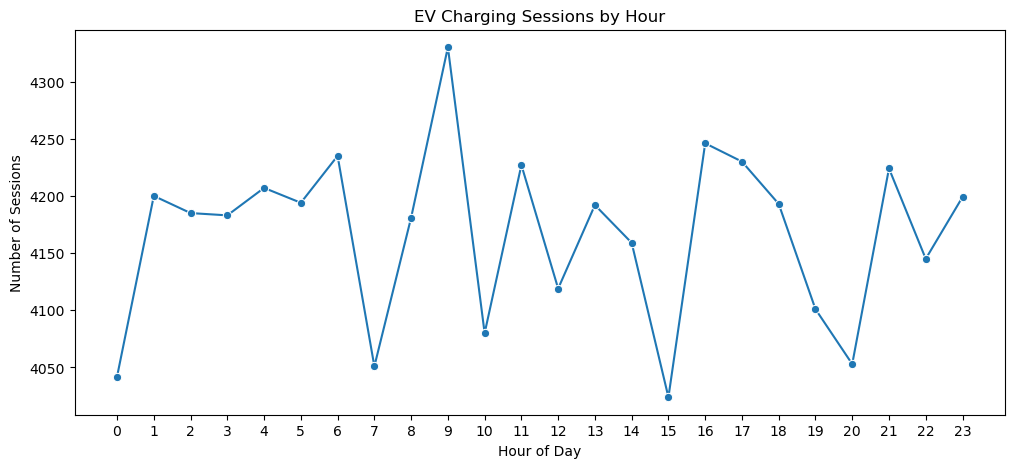

In [25]:
#Analyze charging sessions by hour
hourly_sessions = df_clean['Hour'].value_counts().sort_index()

plt.figure(figsize=(12, 5))
sns.lineplot(
    x=hourly_sessions.index,
    y=hourly_sessions.values,
    marker='o'
)

plt.title('EV Charging Sessions by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Sessions')
plt.xticks(range(24))
plt.show()

In [26]:
df_clean.to_csv(
    r"C:\Users\syeda\Downloads\EV_Cleaned.csv",
    index=False
)